# 2 · Explore: what the market looks like

**Syllabus:** Module 2 (group, sort, rank, plots), Module 3 (descriptive statistics,
correlation).

An idea is only as viable as the market it enters. This chapter describes that market:
how installs and ratings are distributed, which categories are big, crowded or loved,
whether paid apps do better, what users feel, and how the store changed by 2026.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import common as C

C.style()
apps = C.load_apps()
reviews = C.load_reviews()
now = C.load_2026()

## 2.1 Descriptive statistics

Mean, median, variance and standard deviation of the numeric columns. Installs and
reviews are so skewed that their means are dominated by a handful of giants (the mean
is far above the median), so both are also given on a log scale.

In [2]:
num = apps.assign(log_reviews=np.log10(apps["reviews"] + 1))[
    ["rating", "installs", "log_installs", "reviews", "log_reviews", "size_mb", "price", "android"]]
desc = num.agg(["count", "mean", "median", "var", "std", "min", "max"]).T
desc["skew"] = num.skew()
print(desc.round(2))
C.record("explore.describe", desc.round(3).to_dict(orient="index"))

               count        mean     median           var          std   min  \
rating        8196.0        4.17       4.30  2.900000e-01         0.54  1.00   
installs      9659.0  7798170.25  100000.00  2.891184e+15  53769728.82  0.00   
log_installs  9659.0        4.64       5.00  3.650000e+00         1.91  0.00   
reviews       9659.0   216804.11     969.00  3.354137e+12   1831430.21  0.00   
log_reviews   9659.0        2.97       2.99  3.290000e+00         1.81  0.00   
size_mb       8431.0       20.40      12.00  4.765000e+02        21.83  0.01   
price         9659.0        1.10       0.00  2.839800e+02        16.85  0.00   
android       8666.0        3.84       4.00  7.300000e-01         0.85  1.00   

                       max   skew  
rating        5.000000e+00  -1.75  
installs      1.000000e+09  15.03  
log_installs  9.000000e+00  -0.28  
reviews       7.815831e+07  26.57  
log_reviews   7.890000e+00   0.05  
size_mb       1.000000e+02   1.65  
price         4.000000e+02 

## 2.2 Categories: size, demand and quality

Group by category, then rank. "Demand" here is the median installs of an app in the
category, so a few giants do not decide it.

highest success rate: ['ENTERTAINMENT', 'PHOTOGRAPHY', 'EDUCATION', 'GAME', 'WEATHER']
lowest success rate: ['BEAUTY', 'BUSINESS', 'LIBRARIES_AND_DEMO', 'EVENTS', 'MEDICAL']


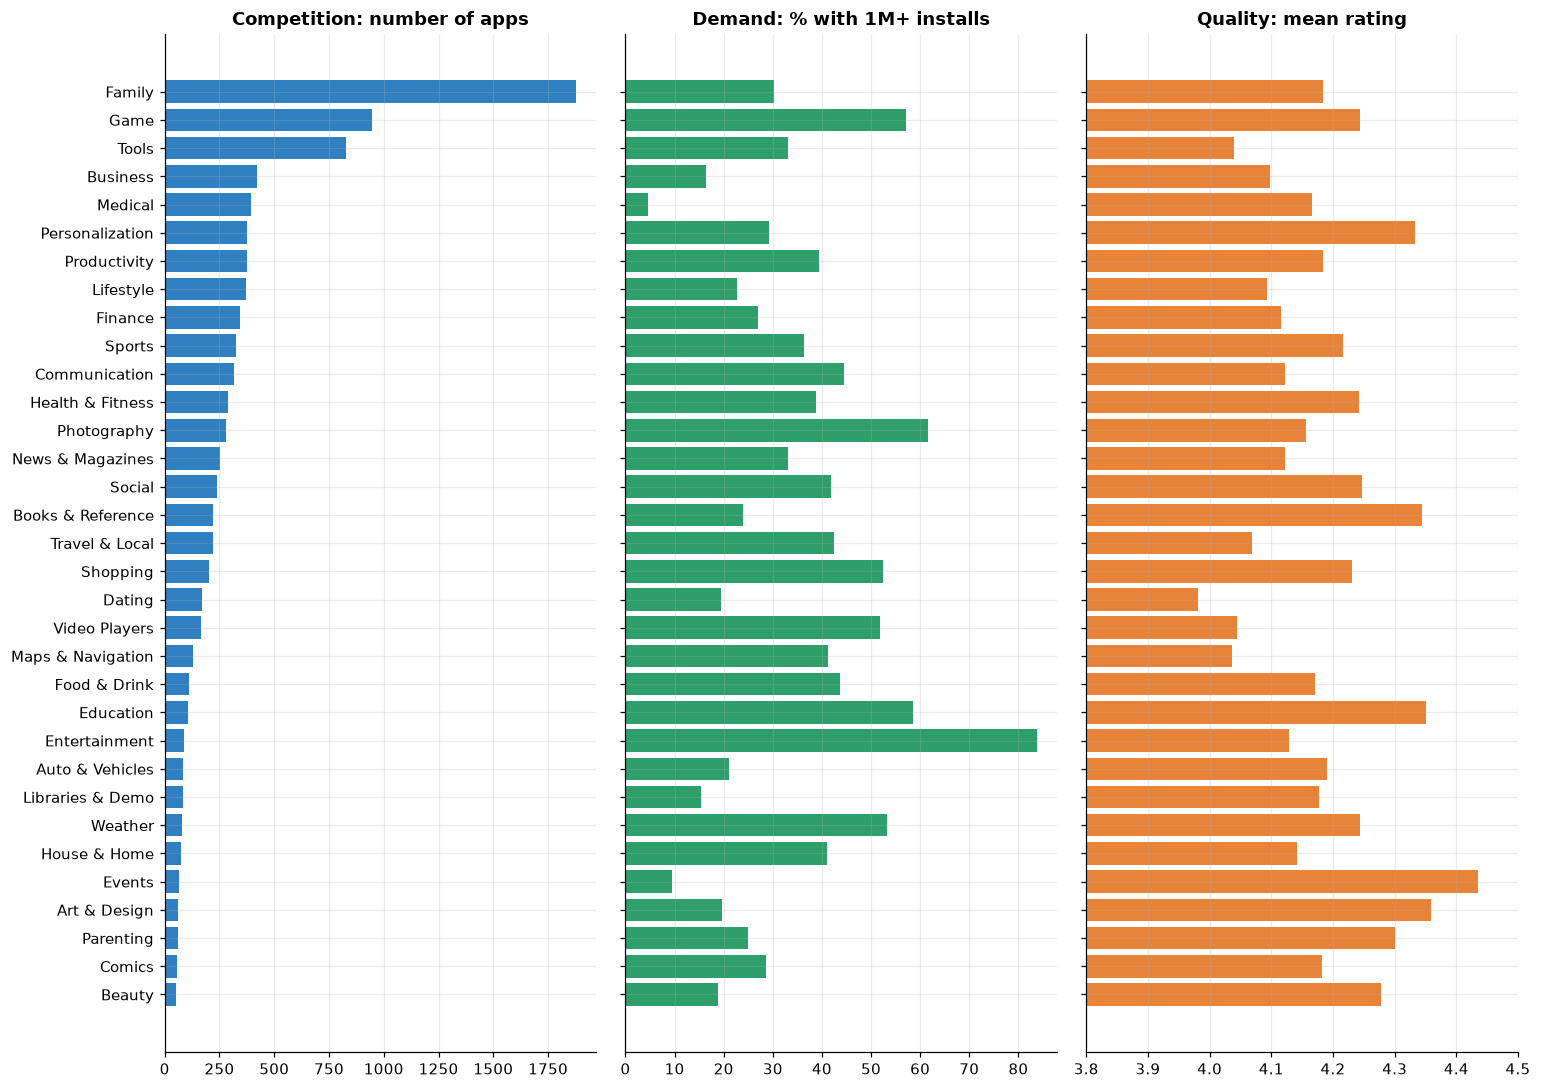

In [3]:
cat = apps.groupby("category").agg(apps=("app", "size"), median_installs=("installs", "median"),
                                   success_rate=("success", "mean"), mean_rating=("rating", "mean"),
                                   paid_share=("paid", "mean")).sort_values("apps", ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(14, 10), sharey=True)
y = np.arange(len(cat))
axes[0].barh(y, cat["apps"], color=C.PALETTE["main"]); axes[0].set_title("Competition: number of apps")
axes[1].barh(y, cat["success_rate"] * 100, color=C.PALETTE["good"]); axes[1].set_title("Demand: % with 1M+ installs")
axes[2].barh(y, cat["mean_rating"], color=C.PALETTE["accent"]); axes[2].set_xlim(3.8, 4.5); axes[2].set_title("Quality: mean rating")
axes[0].set_yticks(y, cat.index.str.replace("_", " ").str.title().str.replace(" And ", " & "), fontsize=10); axes[0].invert_yaxis()
fig.tight_layout(); C.save(fig, "explore_categories")
C.record("explore.categories", cat.round(3).to_dict(orient="index"))
top_demand = cat.sort_values("success_rate", ascending=False)
print("highest success rate:", top_demand.head(5).index.tolist())
print("lowest success rate:", top_demand.tail(5).index.tolist())
C.record("explore.top_success_categories", top_demand.head(5).index.tolist())
C.record("explore.bottom_success_categories", top_demand.tail(5).index.tolist())

Crowded is not the same as popular. FAMILY, the largest category, is not among the five
with the highest success rate, while GAME is both crowded and successful. Medical,
events and business apps are numerous yet rarely become big.

## 2.3 Distributions

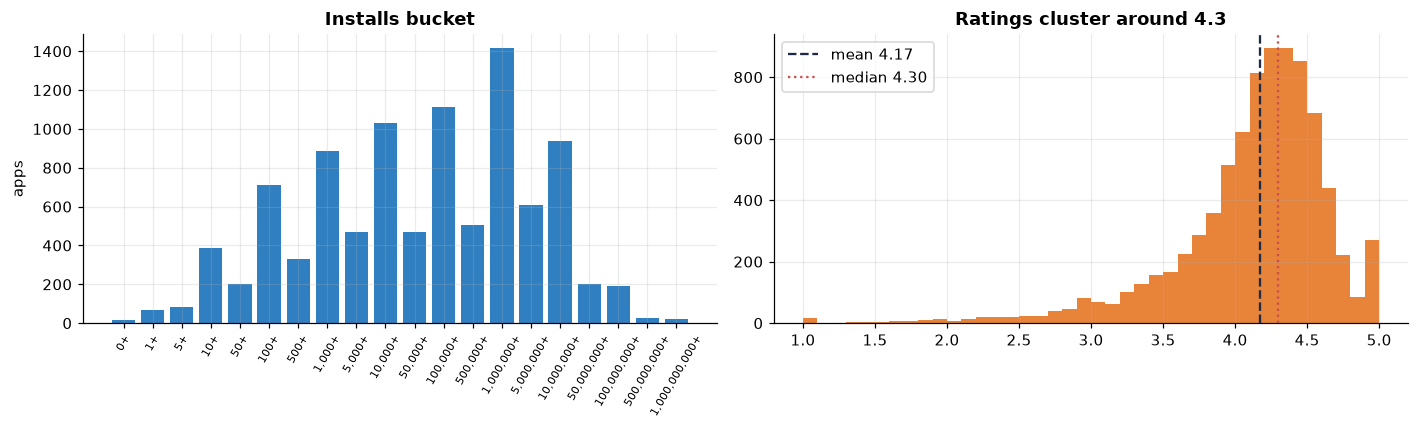

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = sorted(apps["installs"].unique())
counts = apps["installs"].value_counts().reindex(order)
axes[0].bar(range(len(order)), counts.values, color=C.PALETTE["main"])
axes[0].set_xticks(range(len(order)), [f"{v:,}+" for v in order], rotation=60, fontsize=7)
axes[0].set_title("Installs bucket"); axes[0].set_ylabel("apps")
axes[1].hist(apps["rating"].dropna(), bins=np.arange(1, 5.05, 0.1), color=C.PALETTE["accent"])
axes[1].axvline(apps["rating"].mean(), color=C.PALETTE["ink"], ls="--", label=f"mean {apps['rating'].mean():.2f}")
axes[1].axvline(apps["rating"].median(), color=C.PALETTE["bad"], ls=":", label=f"median {apps['rating'].median():.2f}")
axes[1].legend(); axes[1].set_title("Ratings cluster around 4.3")
fig.tight_layout(); C.save(fig, "explore_distributions")

## 2.4 Correlation

Pearson measures straight-line association; Spearman measures whether two columns rise
together at all (on ranks), which suits skewed data like this. Days since the last
update is measured from the newest update in the snapshot.

days_since_update   -0.33
log_price           -0.23
rating               0.03
android              0.05
n_genres             0.10
size_mb              0.31
log_reviews          0.97
log_installs         1.00
Name: log_installs, dtype: float64


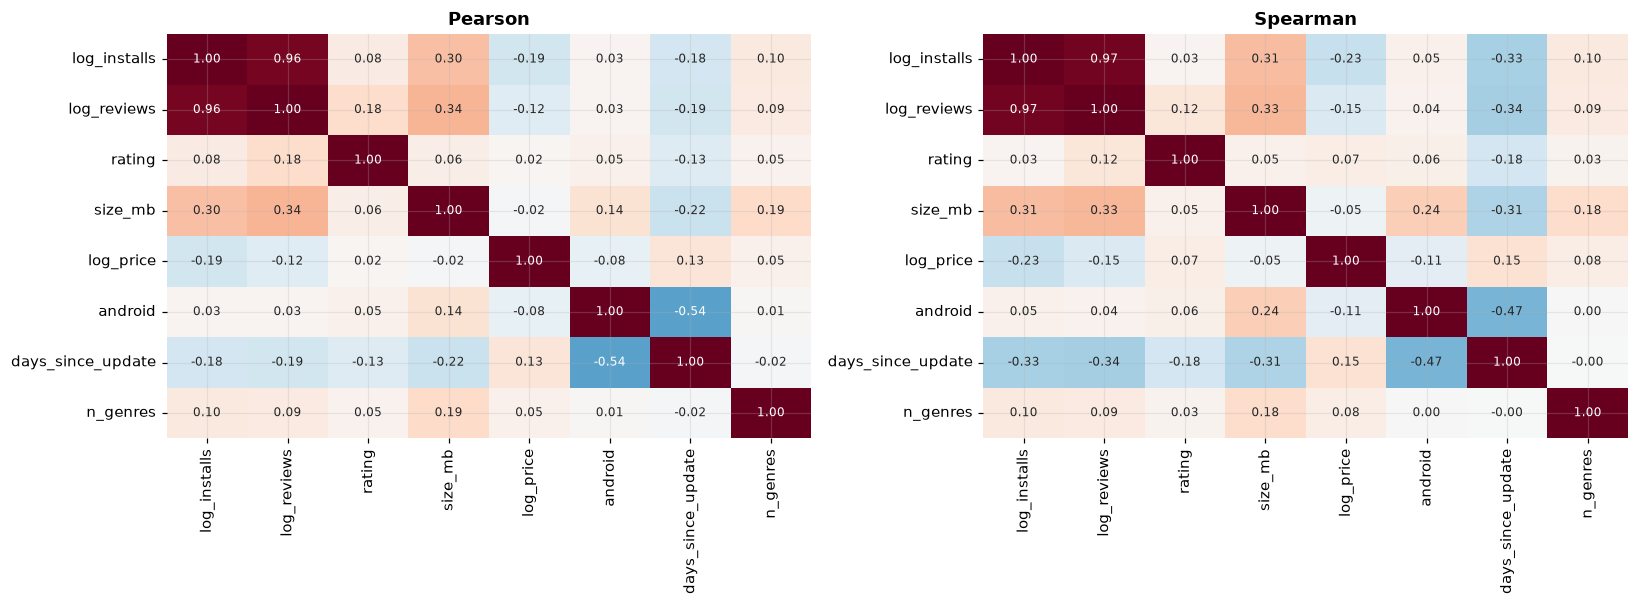

In [5]:
x = apps.assign(log_reviews=np.log10(apps["reviews"] + 1), log_price=np.log1p(apps["price"]),
                days_since_update=(apps["updated"].max() - apps["updated"]).dt.days)
cols = ["log_installs", "log_reviews", "rating", "size_mb", "log_price", "android", "days_since_update", "n_genres"]
pear, spear = x[cols].corr("pearson"), x[cols].corr("spearman")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, m, t in [(axes[0], pear, "Pearson"), (axes[1], spear, "Spearman")]:
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=False, annot_kws={"size": 8})
    ax.set_title(t)
fig.tight_layout(); C.save(fig, "explore_corr")
C.record("explore.corr_spearman", spear.round(3).to_dict())
C.record("explore.corr_pearson", pear.round(3).to_dict())
print(spear["log_installs"].sort_values().round(2))

Reviews and installs move together almost perfectly (more users, more reviews). This
is the most important fact for the rest of the project: reviews and ratings exist
only *after* launch, so they cannot be used to judge an idea. Chapter 3 shows what
happens when they are. Rating itself barely tracks installs. Apps updated recently
have more installs, and so do larger apps.

## 2.5 Free against paid

      apps  median_installs  success_rate  mean_rating
Free  8905         100000.0      0.379113     4.166223
Paid   754           1000.0      0.029178     4.262126


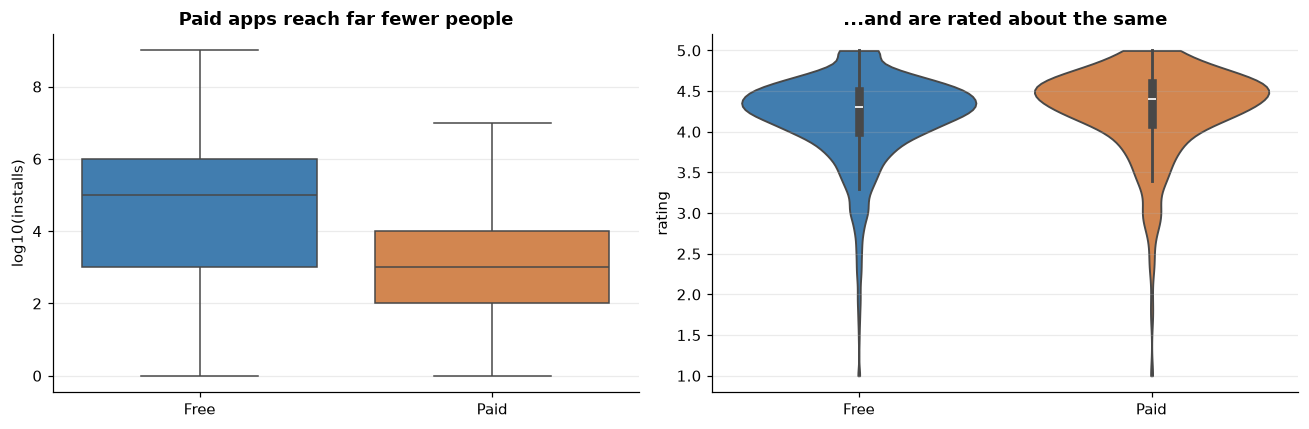

In [6]:
fp = apps.groupby("paid").agg(apps=("app", "size"), median_installs=("installs", "median"),
                              success_rate=("success", "mean"), mean_rating=("rating", "mean"))
fp.index = ["Free", "Paid"]
print(fp)
C.record("explore.free_paid", fp.round(3).to_dict(orient="index"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=apps.assign(type=apps["paid"].map({0: "Free", 1: "Paid"})), x="type", y="log_installs", ax=axes[0],
            hue="type", palette=[C.PALETTE["main"], C.PALETTE["accent"]], legend=False)
axes[0].set_ylabel("log10(installs)"); axes[0].set_xlabel(""); axes[0].set_title("Paid apps reach far fewer people")
sns.violinplot(data=apps.dropna(subset=["rating"]).assign(type=lambda d: d["paid"].map({0: "Free", 1: "Paid"})),
               x="type", y="rating", ax=axes[1], hue="type", palette=[C.PALETTE["main"], C.PALETTE["accent"]], legend=False, cut=0)
axes[1].set_xlabel(""); axes[1].set_title("...and are rated about the same")
fig.tight_layout(); C.save(fig, "explore_free_paid")

## 2.6 What users feel, by category

The review table carries a sentiment label and a polarity from −1 (negative) to +1
(positive). The share of negative reviews per category shows where users are least
happy: a market where users are unhappy is a market where a better app can win.

                    reviews  polarity  negative_share
category                                             
VIDEO_PLAYERS           331     0.144           0.251
FAMILY                 3277     0.136           0.256
NEWS_AND_MAGAZINES     1040     0.128           0.265
SOCIAL                  741     0.109           0.282
GAME                   5947     0.062           0.373


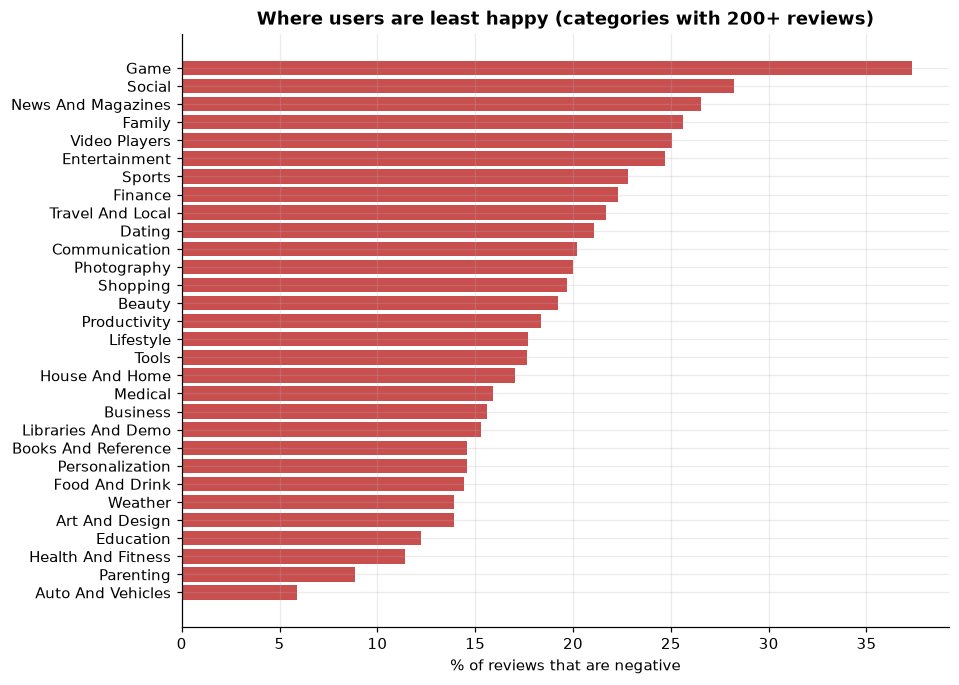

In [7]:
rv = reviews.merge(apps[["app", "category"]], on="app")
sent = rv.groupby("category").agg(reviews=("review", "size"), polarity=("polarity", "mean"),
                                  negative_share=("sentiment", lambda s: (s == "Negative").mean()))
sent = sent[sent["reviews"] >= 200].sort_values("negative_share")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(sent.index.str.replace("_", " ").str.title(), sent["negative_share"] * 100, color=C.PALETTE["bad"])
ax.set_xlabel("% of reviews that are negative"); ax.set_title("Where users are least happy (categories with 200+ reviews)")
C.save(fig, "explore_sentiment")
C.record("explore.sentiment", sent.round(3).to_dict(orient="index"))
print(sent.tail(5).round(3))

## 2.7 Then and now: 2018 against 2026

For each category, the 2018 snapshot against the 2026 scrape. The 2026 sample comes
from search results, which favour popular apps, so its success share is inflated
everywhere. The interesting comparison is therefore *relative*: which categories moved
more than the rest, and how ratings shifted.

{'categories_compared': 30, 'mean_rating_2018': 4.173, 'mean_rating_2026': 4.348, 'paid_share_2018': 0.078, 'paid_share_2026': 0.022, 'rating_up_categories': 25}


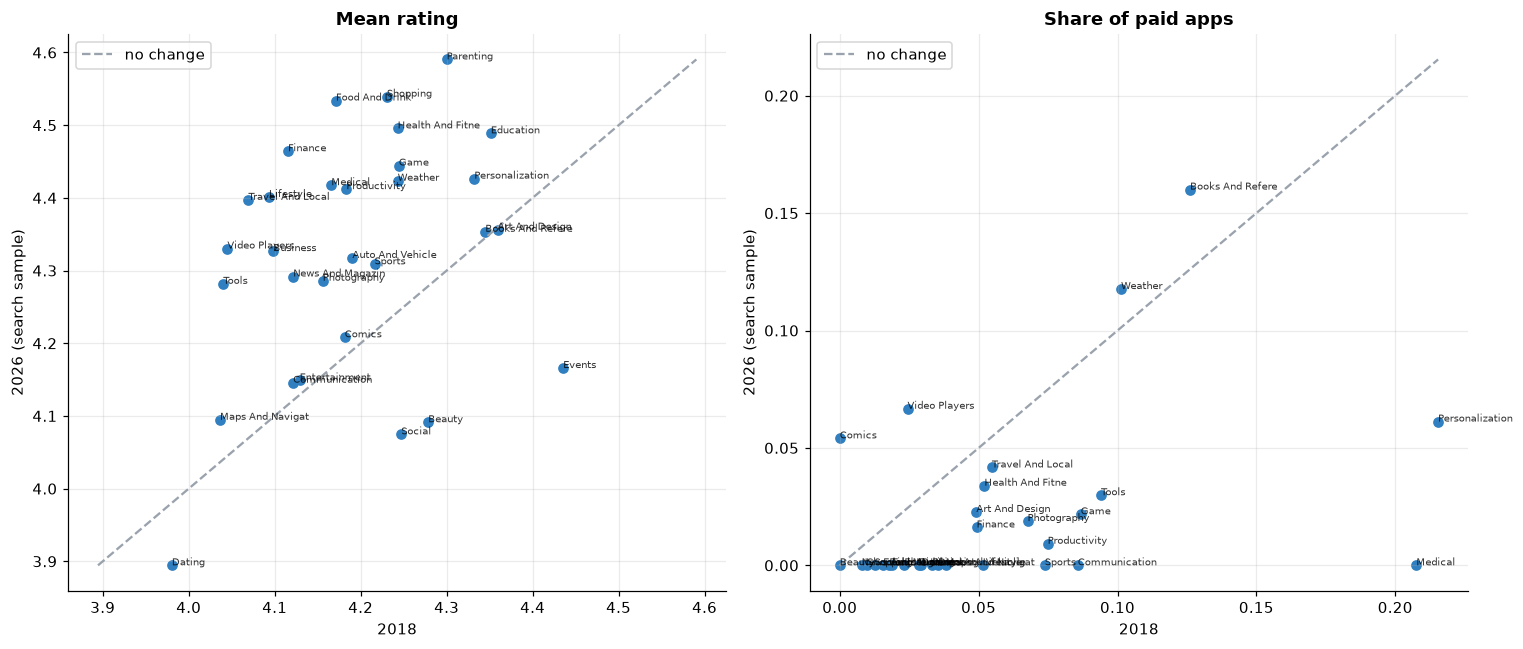

In [8]:
c26 = now.groupby("category").agg(apps_2026=("app", "size"), success_2026=("success", "mean"),
                                  rating_2026=("rating", "mean"), paid_2026=("paid", "mean"))
both = cat.join(c26, how="inner")
both = both[both["apps_2026"] >= 20]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, a, b, t in [(axes[0], "mean_rating", "rating_2026", "Mean rating"), (axes[1], "paid_share", "paid_2026", "Share of paid apps")]:
    ax.scatter(both[a], both[b], color=C.PALETTE["main"])
    for name, r in both.iterrows():
        ax.annotate(name.replace("_", " ").title()[:16], (r[a], r[b]), fontsize=6.5, alpha=0.8)
    lo, hi = min(both[a].min(), both[b].min()), max(both[a].max(), both[b].max())
    ax.plot([lo, hi], [lo, hi], color=C.PALETTE["muted"], ls="--", label="no change")
    ax.set_xlabel("2018"); ax.set_ylabel("2026 (search sample)"); ax.set_title(t); ax.legend()
fig.tight_layout(); C.save(fig, "explore_2018_2026")
change = {"categories_compared": len(both), "mean_rating_2018": round(float(apps["rating"].mean()), 3),
          "mean_rating_2026": round(float(now["rating"].mean()), 3),
          "paid_share_2018": round(float(apps["paid"].mean()), 3), "paid_share_2026": round(float(now["paid"].mean()), 3),
          "rating_up_categories": int((both["rating_2026"] > both["mean_rating"]).sum())}
print(change); C.record("explore.then_now", change)
C.record("explore.then_now_table", both[["mean_rating", "rating_2026", "paid_share", "paid_2026", "apps_2026"]].round(3).to_dict(orient="index"))

Ratings are higher in 2026 in most categories, and paid apps have nearly
disappeared from search results: the store moved to free apps that earn from
subscriptions and in-app purchases. For a new idea, that suggests launching free.